<a href="https://colab.research.google.com/github/kanchanr8595-create/CareFlow-Clinical-Pathway-Process-Mining/blob/development_akshaya/careflow_process_map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install pm4py

In [7]:
import numpy as np
import pandas as pd

df=pd.read_csv("/content/careflow_synthetic_500_patients.csv")

df["timestamp"]=pd.to_datetime(df["timestamp"])

df=df.sort_values(["case_id","event_order"]
)
print(df.head())

  case_id   event_id  event_order             activity           timestamp  \
0   P0001  P0001-E01            1         Registration 2026-09-11 09:54:00   
1   P0001  P0001-E02            2               Triage 2026-09-11 10:20:00   
2   P0001  P0001-E03            3  Doctor Consultation 2026-09-11 11:44:00   
3   P0001  P0001-E04            4             Lab Test 2026-09-11 12:05:00   
4   P0001  P0001-E05            5              Imaging 2026-09-11 13:30:00   

   department journey_type  is_loop_back data_source  
0   Reception       normal         False   synthetic  
1   Emergency       normal         False   synthetic  
2   Emergency       normal         False   synthetic  
3  Laboratory       normal         False   synthetic  
4   Radiology       normal         False   synthetic  


In [8]:
import pm4py

event_log=pm4py.format_dataframe(
    df,
    case_id="case_id",
    activity_key="activity",
    timestamp_key="timestamp"
)

dfg,start_activities,end_activities=(
    pm4py.discover_dfg(event_log)
)

pm4py.save_vis_dfg(
    dfg,
    start_activities,
    end_activities,
    "/content/careflow_process_map.png"
)

''

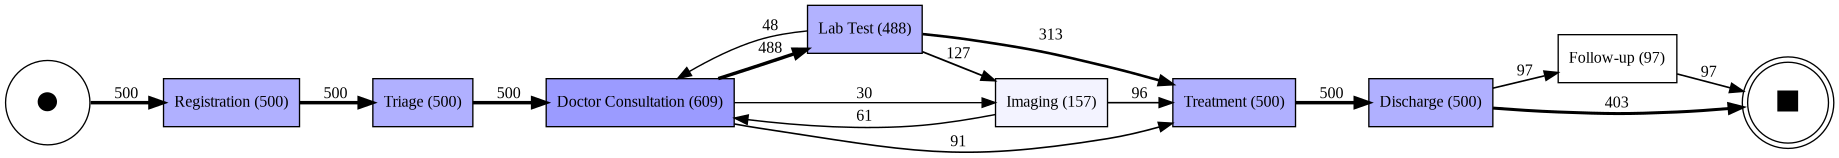

In [10]:
from IPython.display import Image, display

display(Image(filename="/content/careflow_process_map.png"))